--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB
None

--- First 5 Rows ---
                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014 

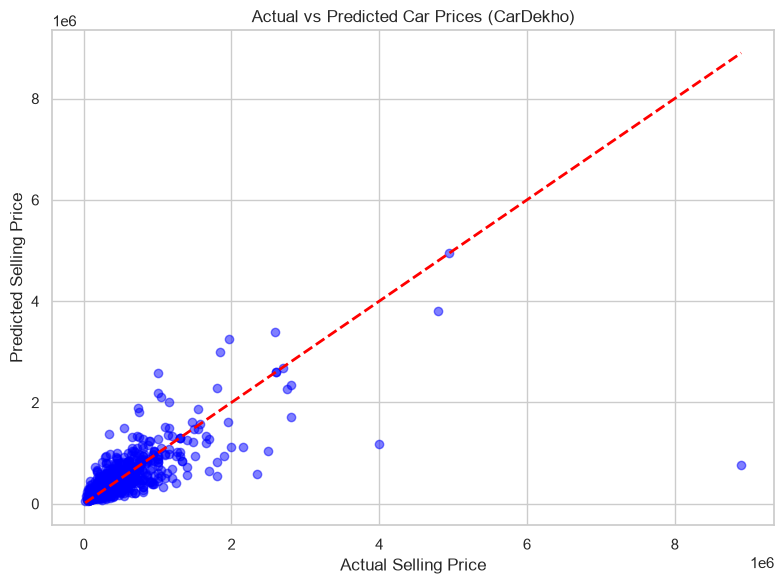

In [2]:
# Import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Set visualization style
sns.set_theme(style="whitegrid")

# 1. Load the dataset using your exact folder path and file name
file_path = r"C:\Users\admin46\OneDrive\studies\grow\OIBSIP\DataScience-Task 3-Overview Car Price Prediction\CAR DETAILS FROM CAR DEKHO.csv"
df = pd.read_csv(file_path)

# 2. Inspect the dataset
print("--- Dataset Info ---")
print(df.info())
print("\n--- First 5 Rows ---")
print(df.head())

# 3. Data Preprocessing & Feature Engineering
current_year = 2026
df["Car_Age"] = current_year - df["year"]

# Drop unnecessary or complex text columns like 'name' and the original 'year'
df = df.drop(columns=["name", "year"])

# Convert categorical columns using One-Hot Encoding
df = pd.get_dummies(df, drop_first=True)

print("\n--- Processed Dataset Preview ---")
print(df.head())

# 4. Define Features (X) and Target (y)
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Model Training (Random Forest Regressor)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 6. Model Evaluation
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score: {r2:.4f}")

# 7. Visualization: Actual vs Predicted Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color="blue", alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    lw=2,
)
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices (CarDekho)")
plt.tight_layout()
plt.show()